In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

In [3]:
data = {
    'Study_Hours': [2, 4, 6, 8, 10, 3, 7, 9],
    'Attendance': [50, 60, 70, 80, 90, 55, 75, 85],
    'Assignment_Score': [40, 50, 60, 75, 90, 45, 70, 85],
    'Internal_Marks': [35, 45, 55, 70, 88, 40, 65, 82]
}

In [4]:
df = pd.DataFrame(data)

print("Original Dataset:")
print(df)


Original Dataset:
   Study_Hours  Attendance  Assignment_Score  Internal_Marks
0            2          50                40              35
1            4          60                50              45
2            6          70                60              55
3            8          80                75              70
4           10          90                90              88
5            3          55                45              40
6            7          75                70              65
7            9          85                85              82


In [5]:
normalizer = MinMaxScaler()
normalized_data = normalizer.fit_transform(df)

In [6]:
normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

print("\nNormalized Dataset:")
print(normalized_df.round(2))


Normalized Dataset:
   Study_Hours  Attendance  Assignment_Score  Internal_Marks
0         0.00        0.00               0.0            0.00
1         0.25        0.25               0.2            0.19
2         0.50        0.50               0.4            0.38
3         0.75        0.75               0.7            0.66
4         1.00        1.00               1.0            1.00
5         0.12        0.12               0.1            0.09
6         0.62        0.62               0.6            0.57
7         0.88        0.88               0.9            0.89


In [7]:
scaler = StandardScaler()
standardized_data = scaler.fit_transform(df)

In [8]:
standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("\nStandardized Dataset:")
print(standardized_df.round(2))


Standardized Dataset:
   Study_Hours  Attendance  Assignment_Score  Internal_Marks
0        -1.52       -1.52             -1.40           -1.37
1        -0.78       -0.78             -0.83           -0.82
2        -0.05       -0.05             -0.25           -0.27
3         0.69        0.69              0.61            0.55
4         1.43        1.43              1.47            1.53
5        -1.15       -1.15             -1.11           -1.10
6         0.32        0.32              0.32            0.27
7         1.06        1.06              1.19            1.20


In [9]:
print("\nMean of standardized features:")
print(standardized_df.mean().round(2))

print("\nStandard deviation of standardized features:")
print(standardized_df.std(ddof=0).round(2))


Mean of standardized features:
Study_Hours         0.0
Attendance          0.0
Assignment_Score    0.0
Internal_Marks      0.0
dtype: float64

Standard deviation of standardized features:
Study_Hours         1.0
Attendance          1.0
Assignment_Score    1.0
Internal_Marks      1.0
dtype: float64


In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(pca_data, columns=['Principal_Component_1','Principal_Component_2'])

In [11]:
print("\nPCA Transformed Dataset:")
print(pca_df.round(2))

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


PCA Transformed Dataset:
   Principal_Component_1  Principal_Component_2
0                  -2.91                   0.14
1                  -1.61                  -0.04
2                  -0.31                  -0.22
3                   1.27                  -0.12
4                   2.93                   0.08
5                  -2.26                   0.05
6                   0.62                  -0.03
7                   2.25                   0.14

Explained Variance Ratio:
[0.9965 0.0034]

Total Variance Retained:
99.99 %


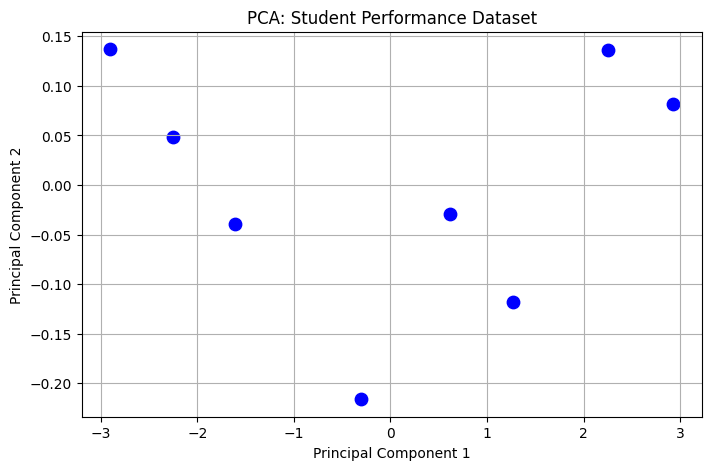

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['Principal_Component_1'],
    pca_df['Principal_Component_2'],
    color='blue',
    s=80
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA: Student Performance Dataset')

plt.grid(True)
plt.show()

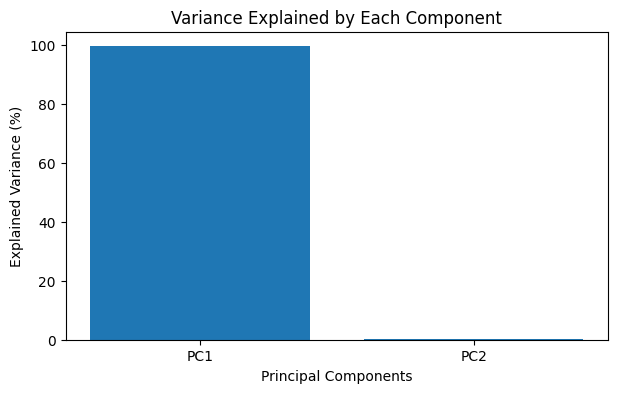

In [13]:
plt.figure(figsize=(7, 4))

components = ['PC1', 'PC2']

plt.bar(
    components,
    pca.explained_variance_ratio_ * 100
)

plt.xlabel('Principal Components')
plt.ylabel('Explained Variance (%)')
plt.title('Variance Explained by Each Component')

plt.show()